# 03 — Resultados, figuras e análise

Avalia os **seis modelos salvos** no mesmo conjunto de teste, **sem novo treinamento**, e gera todas as tabelas e
figuras exigidas (salvas em `figures/` e `results/`).

Protocolo: a **validação** foi usada para parada (perda de validação) e seleção (F1 macro de validação);
o **teste** é usado apenas aqui, uma única vez, sem ajustes posteriores.

In [12]:
# Configuração do ambiente
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Caminho da pasta trashnet-rna no seu Google Drive. Para descobrir: painel "Arquivos"
    # (ícone de pasta à esquerda) -> drive -> MyDrive -> ... -> botão direito na pasta
    # trashnet-rna -> "Copiar caminho", e cole entre as aspas abaixo.
    PROJECT_DIR = "/content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna"
    # As imagens ficam no disco do próprio Colab, que é mais rápido que o Drive.
    os.environ["TRASHNET_DATA_DIR"] = "/content/data"
else:
    PROJECT_DIR = ".."  # rodando no computador, a partir da pasta notebooks/
if not os.path.isdir(os.path.join(PROJECT_DIR, "src", "trashnet")):
    raise FileNotFoundError(f"Não encontrei o projeto em {PROJECT_DIR}. Corrija o PROJECT_DIR acima.")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
print("Projeto:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna


In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from trashnet import config as C
from trashnet import evaluate as E
from trashnet.data import download_dataset, load_split, split_summary

download_dataset()
split_df = load_split()
EXPS = list(C.EXPERIMENTS)
faltando = [e for e in EXPS if not (C.OUTPUT_DIR / e / "model.keras").exists()]
assert not faltando, f"Modelos não encontrados: {faltando}. Rode o notebook 02 ou baixe os modelos (ver README)."

Dataset já disponível em /content/data/dataset-resized


## 1. Distribuição dos dados e exemplos

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_distribuicao_classes.png


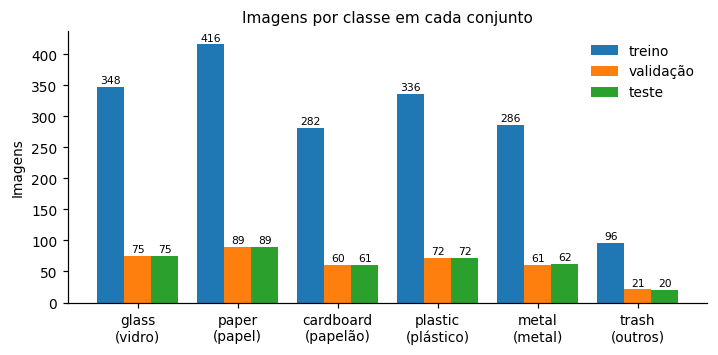

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_exemplos_classes.png


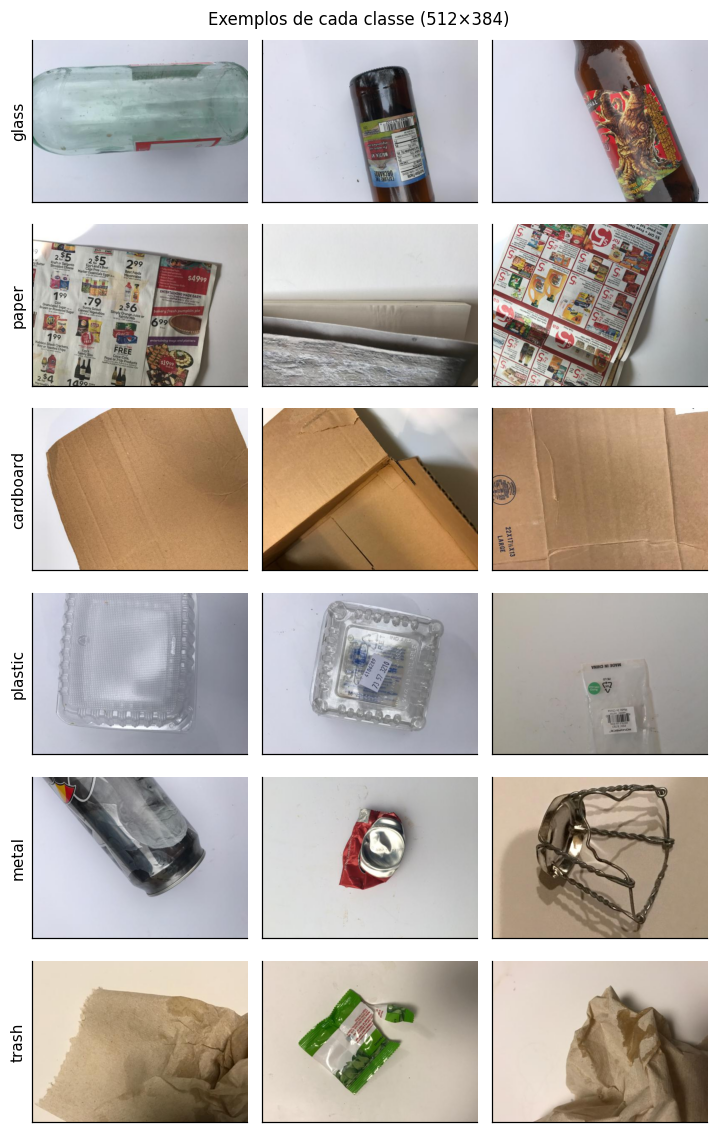

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_resolucoes.png


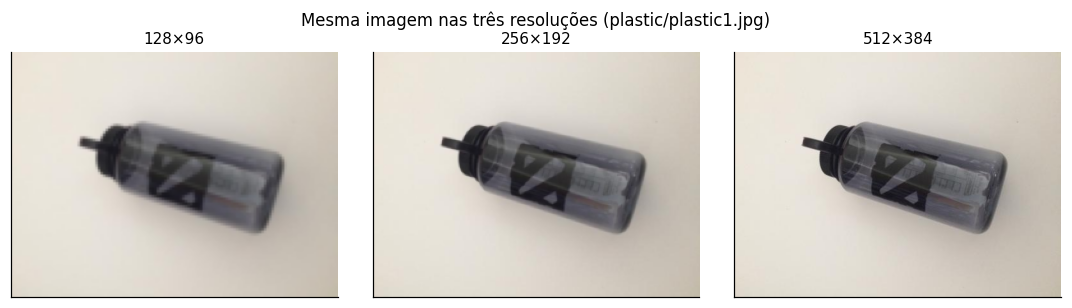

In [14]:
fig = E.plot_class_distribution(split_df); E.save_fig(fig, "fig_distribuicao_classes"); plt.show()
fig = E.plot_examples(split_df, n_per_class=3); E.save_fig(fig, "fig_exemplos_classes"); plt.show()
exemplo = split_df.loc[split_df["label"] == "plastic", "filepath"].iloc[0]
fig = E.plot_same_image_resolutions(exemplo); E.save_fig(fig, "fig_resolucoes"); plt.show()

## 2. Curvas de aprendizagem (perda e acurácia de treino e validação)

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_curvas_aprendizagem.png


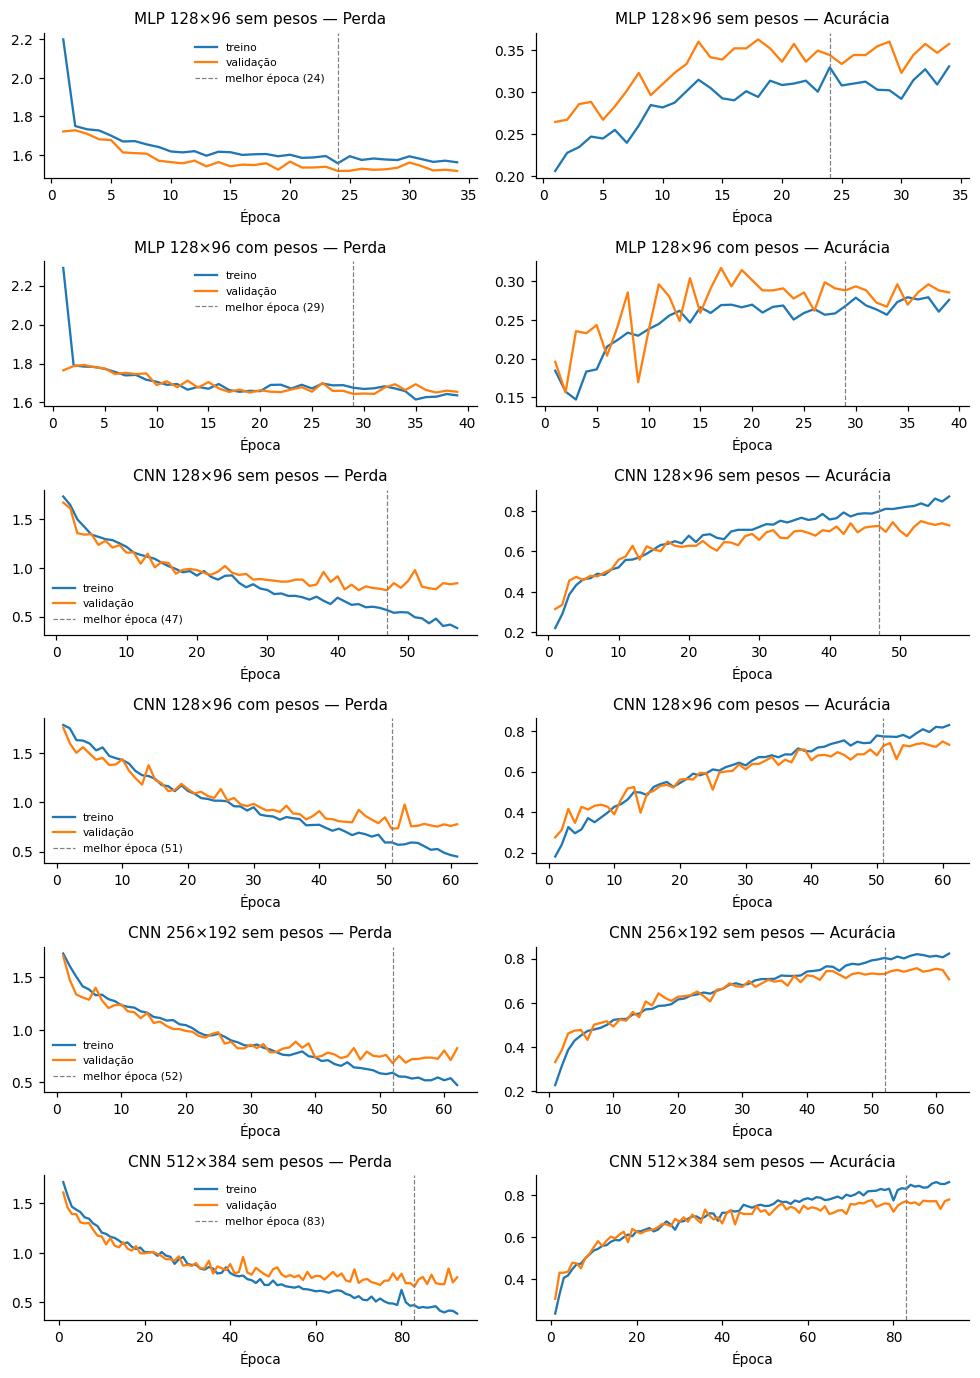

In [5]:
fig = E.plot_learning_curves(EXPS); E.save_fig(fig, "fig_curvas_aprendizagem"); plt.show()

## 3. Validação — seleção de modelo (F1 macro de validação)

In [6]:
resumos = {e: E.load_summary(e) for e in EXPS}
val_preds = {e: E.predict_split(e, split_df, "val") for e in EXPS}
val = pd.DataFrame([{"exp_id": e, "modelo": C.experiment_label(e), **E.global_metrics(p)} for e, p in val_preds.items()])
val = val.rename(columns={"acuracia": "val_acuracia", "f1_macro": "val_f1_macro"})
MELHOR = val.sort_values("val_f1_macro", ascending=False).iloc[0]["exp_id"]
print("Modelo com maior F1 macro de validação:", MELHOR, "—", C.experiment_label(MELHOR))
val.round(4)

Modelo com maior F1 macro de validação: E6_cnn_512x384 — CNN 512×384 sem pesos


,exp_id,modelo,val_acuracia,val_f1_macro
0,E1_mlp_128x96,MLP 128×96 sem pesos,0.3439,0.2400
1,E2_mlp_128x96_pesos,MLP 128×96 com pesos,0.2884,0.1602
2,E3_cnn_128x96,CNN 128×96 sem pesos,0.7249,0.7122
3,E4_cnn_128x96_pesos,CNN 128×96 com pesos,0.7275,0.7097
4,E5_cnn_256x192,CNN 256×192 sem pesos,0.7302,0.6861
5,E6_cnn_512x384,CNN 512×384 sem pesos,0.7698,0.7271


## 4. Teste — métricas e custo dos seis experimentos

In [7]:
test_preds = {e: E.predict_split(e, split_df, "test") for e in EXPS}
linhas = []
for e in EXPS:
    s, m = resumos[e], E.global_metrics(test_preds[e])
    linhas.append({
        "exp_id": e, "modelo": C.experiment_label(e),
        "acuracia_teste": m["acuracia"], "f1_macro_teste": m["f1_macro"],
        "val_f1_macro": float(val.set_index("exp_id").loc[e, "val_f1_macro"]),
        "parametros": s["parametros"], "tamanho_mb": s["tamanho_modelo_mb"],
        "epocas": s["epocas_executadas"], "melhor_epoca": s["melhor_epoca"],
        "tempo_total_s": s["tempo_total_s"], "tempo_medio_epoca_s": s["tempo_medio_epoca_s"],
        "pico_ram_mb": s["pico_ram_mb"], "pico_gpu_mb": s["pico_gpu_mb"],
        "lote": s["hiperparametros_treino"]["batch_size"],
    })
tabela = pd.DataFrame(linhas)
tabela.to_csv(C.RESULTS_DIR / "tabela_metricas_custo.csv", index=False)
print("Hardware:", resumos[EXPS[0]]["hardware"]["gpu"], "|", resumos[EXPS[0]]["hardware"]["cpu"])
print("Medição:", resumos[EXPS[0]]["metodo_medicao"])
tabela.round(4)

Hardware: Tesla T4 | x86_64
Medição: time.perf_counter() em volta do model.fit (sem download e sem leitura das imagens); tempo por época inclui a validação; RAM = maior RSS do processo ao fim das épocas (psutil); GPU = pico do TensorFlow.


,exp_id,modelo,acuracia_teste,f1_macro_teste,val_f1_macro,parametros,tamanho_mb,epocas,melhor_epoca,tempo_total_s,tempo_medio_epoca_s,pico_ram_mb,pico_gpu_mb,lote
0,E1_mlp_128x96,MLP 128×96 sem pesos,0.3694,0.2509,0.2400,9471110,36.16,34,24,25.3,0.73,1783,329,32
1,E2_mlp_128x96_pesos,MLP 128×96 com pesos,0.2955,0.1700,0.1602,9471110,36.16,39,29,24.8,0.63,1849,411,32
2,E3_cnn_128x96,CNN 128×96 sem pesos,0.7282,0.7109,0.7122,405254,1.60,57,47,75.8,1.32,2180,1012,32
3,E4_cnn_128x96_pesos,CNN 128×96 com pesos,0.7177,0.7044,0.7097,405254,1.60,61,51,71.6,1.17,2237,617,32
4,E5_cnn_256x192,CNN 256×192 sem pesos,0.7467,0.7189,0.6861,405254,1.60,62,52,237.5,3.82,3119,2842,32
5,E6_cnn_512x384,CNN 512×384 sem pesos,0.7863,0.7616,0.7271,405254,1.60,93,83,1299.1,13.94,5127,7969,32


### Precisão, recall, F1 e suporte por classe (teste)

In [8]:
relatorios = []
for e in EXPS:
    r = E.per_class_report(test_preds[e]); r.insert(0, "exp_id", e)
    relatorios.append(r)
por_classe = pd.concat(relatorios, ignore_index=True)
por_classe.to_csv(C.RESULTS_DIR / "tabela_metricas_por_classe.csv", index=False)
for e in EXPS:
    print(f"\n=== {e} — {C.experiment_label(e)} ===")
    display(por_classe[por_classe.exp_id == e].drop(columns="exp_id").round(3))


=== E1_mlp_128x96 — MLP 128×96 sem pesos ===


,classe,precisao,recall,f1,suporte
0,glass,0.000,0.000,0.000,75
1,paper,0.277,0.461,0.346,89
2,cardboard,0.689,0.689,0.689,61
3,plastic,0.335,0.792,0.471,72
4,metal,0.000,0.000,0.000,62
5,trash,0.000,0.000,0.000,20



=== E2_mlp_128x96_pesos — MLP 128×96 com pesos ===


,classe,precisao,recall,f1,suporte
6,glass,0.000,0.000,0.000,75
7,paper,0.273,0.034,0.060,89
8,cardboard,0.506,0.689,0.583,61
9,plastic,0.236,0.931,0.376,72
10,metal,0.000,0.000,0.000,62
11,trash,0.000,0.000,0.000,20



=== E3_cnn_128x96 — CNN 128×96 sem pesos ===


,classe,precisao,recall,f1,suporte
12,glass,0.697,0.613,0.652,75
13,paper,0.726,0.865,0.790,89
14,cardboard,0.898,0.721,0.800,61
15,plastic,0.701,0.750,0.725,72
16,metal,0.662,0.726,0.692,62
17,trash,0.769,0.500,0.606,20


... (2 outputs left out)


=== E5_cnn_256x192 — CNN 256×192 sem pesos ===


,classe,precisao,recall,f1,suporte
24,glass,0.724,0.733,0.728,75
25,paper,0.731,0.854,0.788,89
26,cardboard,0.927,0.836,0.879,61
27,plastic,0.804,0.625,0.703,72
28,metal,0.667,0.742,0.702,62
29,trash,0.526,0.500,0.513,20



=== E6_cnn_512x384 — CNN 512×384 sem pesos ===


,classe,precisao,recall,f1,suporte
30,glass,0.759,0.800,0.779,75
31,paper,0.837,0.865,0.851,89
32,cardboard,0.942,0.803,0.867,61
33,plastic,0.743,0.764,0.753,72
34,metal,0.708,0.742,0.724,62
35,trash,0.647,0.550,0.595,20


In [9]:
# Visão compacta: F1 por classe em cada experimento
pivot_f1 = por_classe.pivot(index="classe", columns="exp_id", values="f1").reindex(C.CLASSES)
pivot_f1.round(3)

exp_id,E1_mlp_128x96,E2_mlp_128x96_pesos,E3_cnn_128x96,E4_cnn_128x96_pesos,E5_cnn_256x192,E6_cnn_512x384
classe,,,,,,
glass,0.000,0.000,0.652,0.675,0.728,0.779
paper,0.346,0.060,0.790,0.773,0.788,0.851
cardboard,0.689,0.583,0.800,0.857,0.879,0.867
plastic,0.471,0.376,0.725,0.667,0.703,0.753
metal,0.000,0.000,0.692,0.650,0.702,0.724
trash,0.000,0.000,0.606,0.605,0.513,0.595


## 5. Matrizes de confusão (contagem e % por linha; reais nas linhas)

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_matrizes_confusao.png


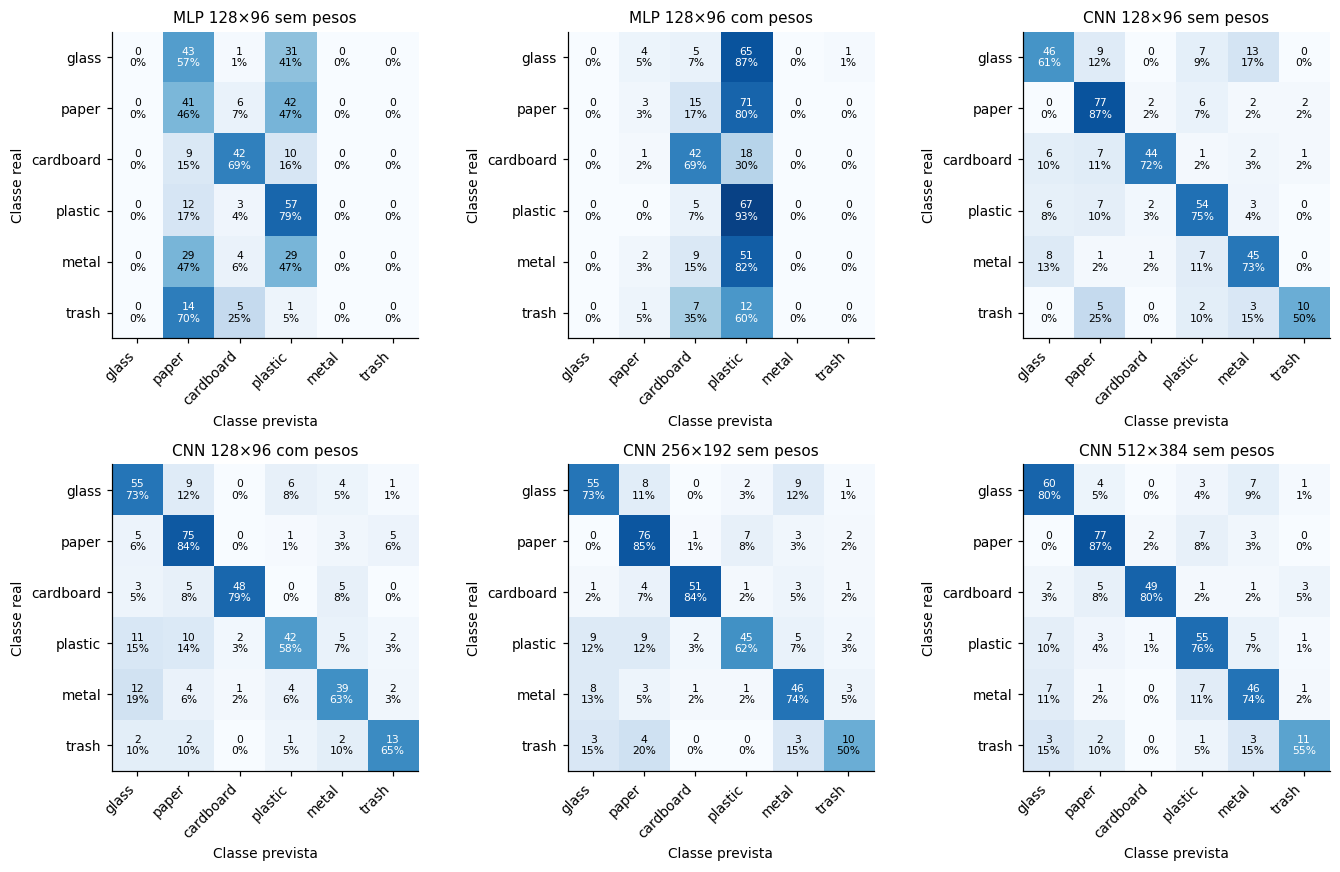

In [10]:
fig = E.plot_confusions(test_preds); E.save_fig(fig, "fig_matrizes_confusao"); plt.show()

## 6. Efeito dos pesos de classe

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_efeito_pesos.png


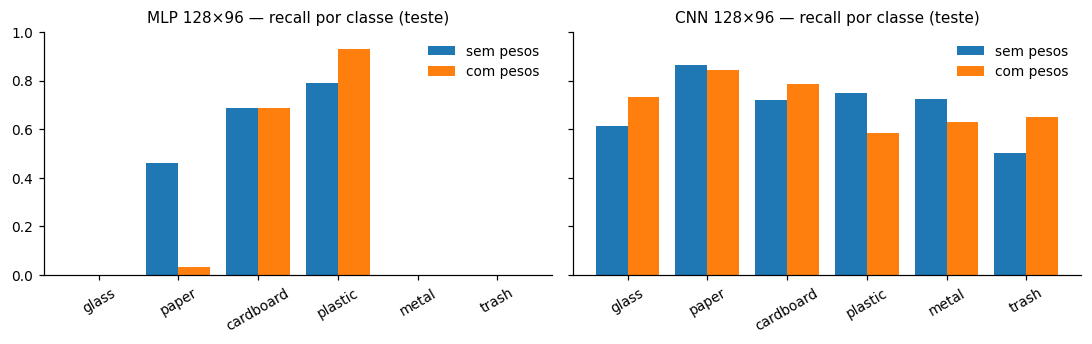

,modelo,classe,recall_sem,recall_com,precisao_sem,precisao_com,f1_sem,f1_com,delta_f1
0,MLP,glass,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,MLP,paper,0.461,0.034,0.277,0.273,0.346,0.060,-0.286
2,MLP,cardboard,0.689,0.689,0.689,0.506,0.689,0.583,-0.105
3,MLP,plastic,0.792,0.931,0.335,0.236,0.471,0.376,-0.095
4,MLP,metal,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,MLP,trash,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,CNN,glass,0.613,0.733,0.697,0.625,0.652,0.675,0.022
7,CNN,paper,0.865,0.843,0.726,0.714,0.790,0.773,-0.017
8,CNN,cardboard,0.721,0.787,0.898,0.941,0.800,0.857,0.057
9,CNN,plastic,0.750,0.583,0.701,0.778,0.725,0.667,-0.058


In [11]:
pares = [("E1_mlp_128x96", "E2_mlp_128x96_pesos"), ("E3_cnn_128x96", "E4_cnn_128x96_pesos")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
comp = []
for ax, (sem, com) in zip(axes, pares):
    a = por_classe[por_classe.exp_id == sem].set_index("classe")
    b = por_classe[por_classe.exp_id == com].set_index("classe")
    x = np.arange(len(C.CLASSES))
    ax.bar(x - 0.2, a.loc[C.CLASSES, "recall"], 0.4, label="sem pesos")
    ax.bar(x + 0.2, b.loc[C.CLASSES, "recall"], 0.4, label="com pesos")
    ax.set_xticks(x, C.CLASSES, rotation=30); ax.set_ylim(0, 1)
    ax.set_title(f"{C.EXPERIMENTS[sem]['model'].upper()} 128×96 — recall por classe (teste)")
    ax.legend(frameon=False)
    for c in C.CLASSES:
        comp.append({"modelo": C.EXPERIMENTS[sem]["model"].upper(), "classe": c,
                     "recall_sem": a.loc[c, "recall"], "recall_com": b.loc[c, "recall"],
                     "precisao_sem": a.loc[c, "precisao"], "precisao_com": b.loc[c, "precisao"],
                     "f1_sem": a.loc[c, "f1"], "f1_com": b.loc[c, "f1"]})
fig.tight_layout(); E.save_fig(fig, "fig_efeito_pesos"); plt.show()
comp = pd.DataFrame(comp); comp["delta_f1"] = comp["f1_com"] - comp["f1_sem"]
comp.to_csv(C.RESULTS_DIR / "tabela_efeito_pesos.csv", index=False)
comp.round(3)

## 7. Efeito da resolução na CNN (sem pesos)

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_efeito_resolucao.png


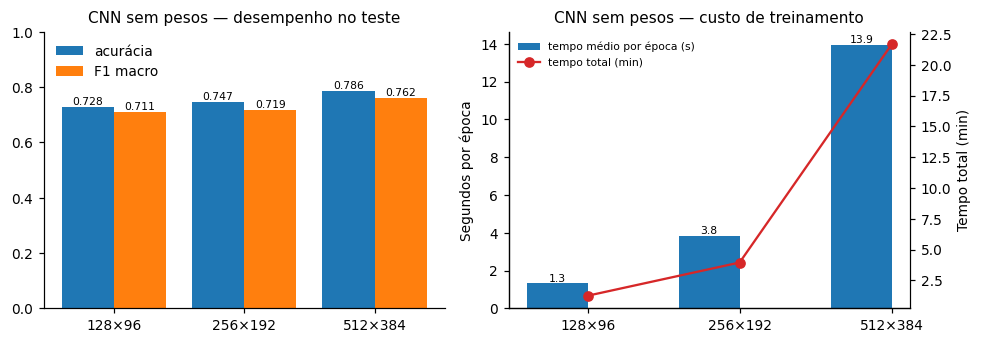

,resolucao,acuracia,f1_macro,parametros,epocas,tempo_medio_epoca_s,tempo_total_s,pico_ram_mb,pico_gpu_mb
0,128×96,0.728,0.711,405254,57,1.32,75.8,2180,1012
1,256×192,0.747,0.719,405254,62,3.82,237.5,3119,2842
2,512×384,0.786,0.762,405254,93,13.94,1299.1,5127,7969


In [15]:
res_ids = ["E3_cnn_128x96", "E5_cnn_256x192", "E6_cnn_512x384"]
res = tabela.set_index("exp_id").loc[res_ids].reset_index()
res["resolucao"] = [f"{C.EXPERIMENTS[e]['size'][0]}×{C.EXPERIMENTS[e]['size'][1]}" for e in res_ids]
res = res.rename(columns={"acuracia_teste": "acuracia", "f1_macro_teste": "f1_macro"})
fig = E.plot_resolution_effect(res); E.save_fig(fig, "fig_efeito_resolucao"); plt.show()
res[["resolucao", "acuracia", "f1_macro", "parametros", "epocas", "tempo_medio_epoca_s",
     "tempo_total_s", "pico_ram_mb", "pico_gpu_mb"]].round(3)

## 8. Análise dos erros do modelo com maior F1 macro de validação

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_erros_melhor_modelo.png


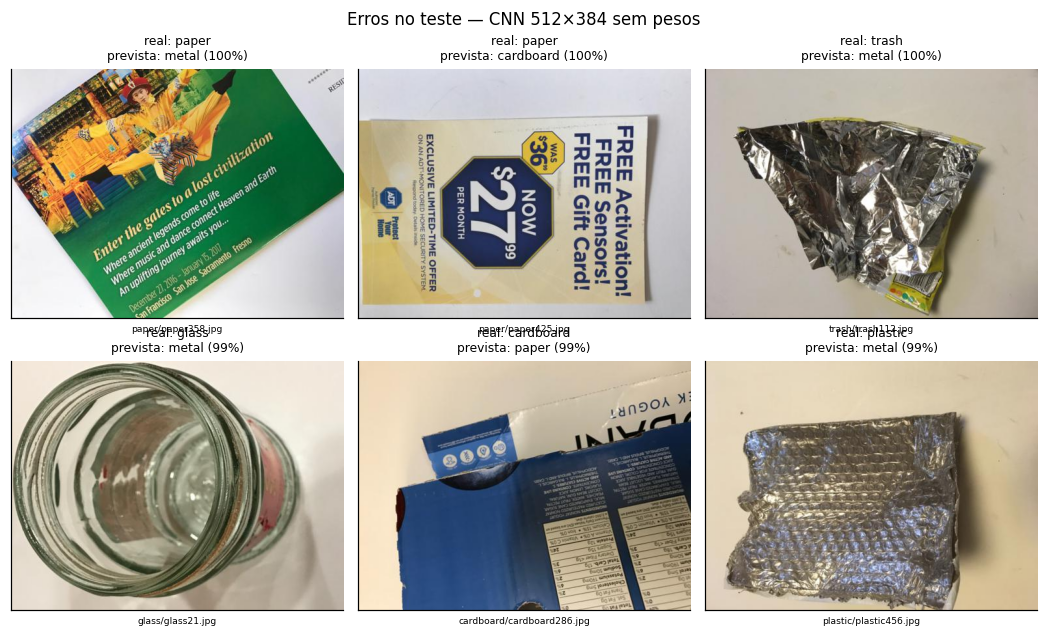

Total de erros no teste: 81 de 379


,filepath,label,pred,prob_pred
116,paper/paper358.jpg,paper,metal,0.999811
129,paper/paper425.jpg,paper,cardboard,0.999432
363,trash/trash112.jpg,trash,metal,0.998055
20,glass/glass21.jpg,glass,metal,0.994945
193,cardboard/cardboard286.jpg,cardboard,paper,0.994645
284,plastic/plastic456.jpg,plastic,metal,0.987969
214,cardboard/cardboard41.jpg,cardboard,paper,0.985841
196,cardboard/cardboard294.jpg,cardboard,paper,0.979553
121,paper/paper382.jpg,paper,plastic,0.964816
13,glass/glass186.jpg,glass,metal,0.943096


In [16]:
fig, erros = E.plot_errors(test_preds[MELHOR], f"Erros no teste — {C.experiment_label(MELHOR)}", n=6)
if fig is not None:
    E.save_fig(fig, "fig_erros_melhor_modelo"); plt.show()
print(f"Total de erros no teste: {len(erros)} de {len(test_preds[MELHOR])}")
erros.to_csv(C.RESULTS_DIR / f"erros_teste_{MELHOR}.csv", index=False)
erros[["filepath", "label", "pred", "prob_pred"]].sort_values("prob_pred", ascending=False).head(15)

In [17]:
# Pares de confusão mais frequentes do melhor modelo
erros.groupby(["label", "pred"]).size().sort_values(ascending=False).rename("quantidade").to_frame().head(10)

quantidade
label     pred               
glass     metal             7
plastic   glass             7
paper     plastic           7
metal     plastic           7
          glass             7
cardboard paper             5
plastic   metal             5
glass     paper             4
          plastic           3
trash     metal             3

## 9. Discussão

A discussão completa está na **Seção 4 do artigo** ([`artigo/artigo_trashnet.pdf`](../artigo/artigo_trashnet.pdf)).
Resumo dos principais pontos, com os números das tabelas acima:

- **Arquiteturas:** em 128×96, a CNN obteve F1 macro de teste de 0,711, contra 0,251 da MLP, com 23 vezes menos parâmetros.
  As curvas mostram subajuste da MLP (acurácia de treino abaixo de 0,34) e sobreajuste moderado das CNNs após a época 20–25,
  contido pelo *early stopping*.
- **Desequilíbrio:** na CNN, os pesos de classe elevaram o *recall* de *trash* de 0,50 para 0,65, mas reduziram a precisão
  da classe e o *recall* de *plastic* e *metal*; o F1 macro ficou praticamente igual (0,711 → 0,704). Na MLP, pioraram o
  resultado (0,251 → 0,170). Nas classes que a MLP nunca previu, a precisão é 0/0 e foi registrada como 0
  (`zero_division=0`).
- **Resolução e custo:** em 512×384 o F1 macro subiu para 0,762 (+0,051), com 10,6 vezes mais tempo por época,
  17,1 vezes mais tempo total e 7,9 vezes mais memória de GPU; 256×192 não justificou o custo.
- **Erros:** as confusões mais comuns envolvem vidro, plástico e metal (reflexos e transparência) e papel × papelão.
- **Comparação com Yang e Thung (2016):** os 78,6 % da CNN E6 não são diretamente comparáveis aos 63 % (SVM, seis classes)
  e 22 % (CNN, cinco classes, sem *trash*) do artigo, por diferenças de classes, divisão, resolução e treinamento.